# Team Rhone: Wine Review Authorship Models

Stylometric & Syntactic Feature Extraction + LightGBM / Random Forest

### 1. Imports & Setup

In [1]:
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
import textstat
import kagglehub

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from lightgbm import LGBMClassifier

# Load spaCy language model for POS tagging
nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])

# Set random seed for reproducibility
RANDOM_STATE = 4401
SEED = 4401
random.seed(SEED)
np.random.seed(SEED)

### 2. Data Download & Cleanup

In [2]:
# 1. Download latest version of the dataset via kagglehub
path = Path(kagglehub.dataset_download("zynicide/wine-reviews"))
INPUT_FILE = path / "winemag-data-130k-v2.csv"

print("Dataset directory:", path)
print("Path to dataset files:", INPUT_FILE)

# 2. Load dataset
df = pd.read_csv(INPUT_FILE)
print("Dataset shape:", df.shape)
display(df.head())

# --------------------------- DATA PREPARATION ---------------------------
MIN_REVIEWS_PER_AUTHOR = 300
N_AUTHORS = 16
REVIEWS_PER_AUTHOR = 300

# Keep non-null reviewer and description entries
model_data = df.dropna(subset=["taster_name", "description"]).copy()
model_data["taster_name"] = model_data["taster_name"].astype(str).str.strip()
model_data["description"] = model_data["description"].astype(str).str.strip()
model_data = model_data[(model_data["taster_name"] != "") & (model_data["description"] != "")].copy()

# Remove repeated descriptions to prevent train/test leakage
rows_before_deduplication = len(model_data)
description_frequency = model_data["description"].value_counts()
model_data = model_data[model_data["description"].map(description_frequency).eq(1)].copy()
print(f"Removed {rows_before_deduplication - len(model_data):,} rows with duplicate review text.")

# Select prolific reviewers and sample a balanced dataset across authors
author_counts = model_data["taster_name"].value_counts()
selected_authors = author_counts[author_counts >= MIN_REVIEWS_PER_AUTHOR].head(N_AUTHORS).index.tolist()
selected = model_data[model_data["taster_name"].isin(selected_authors)].copy()

sample_size = min(REVIEWS_PER_AUTHOR, selected["taster_name"].value_counts().min())
balanced = (
    selected.groupby("taster_name", group_keys=False)
    .sample(n=sample_size, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

print(f"Modeling dataset: {len(balanced):,} reviews")
print(f"Reviewers: {len(selected_authors)}")
print(f"Reviews per reviewer: {sample_size}")

display(
    pd.DataFrame({
        "reviewer": selected_authors,
        "reviews_in_cleaned_dataset": [author_counts[a] for a in selected_authors]
    })
)

Using Colab cache for faster access to the 'wine-reviews' dataset.
Dataset directory: /kaggle/input/wine-reviews
Path to dataset files: /kaggle/input/wine-reviews/winemag-data-130k-v2.csv
Dataset shape: (129971, 14)


,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


Removed 17,362 rows with duplicate review text.
Modeling dataset: 4,800 reviews
Reviewers: 16
Reviews per reviewer: 300


,reviewer,reviews_in_cleaned_dataset
0,Roger Voss,21602
1,Michael Schachner,12957
2,Kerin O’Keefe,8584
3,Paul Gregutt,8203
4,Virginie Boone,7878
5,Matt Kettmann,5127
6,Joe Czerwinski,4382
7,Sean P. Sullivan,3955
8,Anna Lee C. Iijima,3619
9,Jim Gordon,3355


### 3. Metadata Masking

In [3]:
# List of metadata columns containing terms to mask in review text
MASK_COLUMNS = [
    "country", "province", "region_1", "region_2",
    "variety", "winery", "designation"
]

def mask_metadata_terms(row):
    """
    Replace specific place, variety, and winery names associated with this wine
    with a generic [MASK] token to prevent geographic/domain target leakage.
    """
    text = row["description"]
    names = {
        str(row[col]) for col in MASK_COLUMNS
        if pd.notna(row[col]) and len(str(row[col])) >= 3
    }
    # Mask longest names first so "Russian River Valley" is masked before "Valley"
    for name in sorted(names, key=len, reverse=True):
        text = re.sub(re.escape(name), "[MASK]", text, flags=re.IGNORECASE)
    return text

print("Masking metadata terms across review descriptions...")
balanced["masked_description"] = balanced.apply(mask_metadata_terms, axis=1)

Masking metadata terms across review descriptions...


### 4. Writing Style & Grammar Extraction

In [12]:
# --- Batch Feature Extraction ---
def extract_stylometrics_from_docs(docs, df):
    feature_list = []

    for doc, (_, row) in zip(docs, df.iterrows()):
        text = row["masked_description"]
        words = [token.text.lower() for token in doc if token.is_alpha]
        num_words = len(words)
        num_sentences = max(len(list(doc.sents)), 1)
        char_count = max(len(text), 1)

        if num_words == 0:
            feature_list.append({})
            continue

        unique_words = len(set(words))
        pos_counts = doc.count_by(spacy.attrs.POS)

        adj_c = pos_counts.get(spacy.symbols.ADJ, 0)
        noun_c = pos_counts.get(spacy.symbols.NOUN, 0)
        adv_c = pos_counts.get(spacy.symbols.ADV, 0)
        verb_c = pos_counts.get(spacy.symbols.VERB, 0)
        propn_c = pos_counts.get(spacy.symbols.PROPN, 0)

        # Readability & Lexical Metrics
        ttr = unique_words / num_words
        log_ttr = np.log(unique_words) / np.log(num_words) if num_words > 1 else 0
        avg_word_len = np.mean([len(w) for w in words])
        avg_sent_len = num_words / num_sentences
        fk_grade = textstat.flesch_kincaid_grade(text)
        ari_score = textstat.automated_readability_index(text)

        # Punctuation Densities
        comma_rate = (text.count(",") / char_count) * 100
        dash_rate = ((text.count("-") + text.count("—")) / char_count) * 100
        semicolon_rate = (text.count(";") / char_count) * 100
        exclamation_rate = (text.count("!") / char_count) * 100
        paren_rate = ((text.count("(") + text.count(")")) / char_count) * 100

        # POS Ratios & CLR
        pos_counts_arr = np.array([adj_c, noun_c, adv_c, verb_c, propn_c]) + 0.5
        log_pos = np.log(pos_counts_arr)
        clr_pos = log_pos - log_pos.mean()

        feature_list.append({
            "ttr": ttr,
            "log_ttr": log_ttr,
            "avg_word_len": avg_word_len,
            "avg_sent_len": avg_sent_len,
            "flesch_kincaid": fk_grade,
            "ari_score": ari_score,
            "comma_rate": comma_rate,
            "dash_rate": dash_rate,
            "semicolon_rate": semicolon_rate,
            "exclamation_rate": exclamation_rate,
            "paren_rate": paren_rate,
            "adj_rate": adj_c / num_words,
            "noun_rate": noun_c / num_words,
            "adv_rate": adv_c / num_words,
            "verb_rate": verb_c / num_words,
            "propn_rate": propn_c / num_words,
            "adj_noun_ratio": adj_c / max(noun_c, 1),
            "adv_verb_ratio": adv_c / max(verb_c, 1),
            "adj_clr": clr_pos[0],
            "noun_clr": clr_pos[1],
            "adv_clr": clr_pos[2],
            "verb_clr": clr_pos[3],
            "propn_clr": clr_pos[4],
            "points": row["points"] if pd.notna(row["points"]) else 88.0,
            "price": row["price"] if pd.notna(row["price"]) else 25.0,
        })
    return pd.DataFrame(feature_list)

print("Extracting enhanced features in batch...")
# Process documents in batches of 256 for optimal CPU throughput
docs = list(nlp.pipe(balanced["masked_description"], batch_size=256, n_process=2))
X_stylo = extract_stylometrics_from_docs(docs, balanced)
y = balanced["taster_name"]

Extracting enhanced features in batch...


## 5. Model Training & Hyperparameter Tuning

In [13]:
# --- Train / Test Split & Feature Scaling ---
X_train, X_test, y_train, y_test = train_test_split(
    X_stylo, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Scale features while preserving feature names for interpretability
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# --- Model 1: Random Forest Baseline ---
rf_model = RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)
rf_pred = rf_model.predict(X_test_scaled)

# --- Model 2: Expanded Tuned LightGBM ---
lgbm = LGBMClassifier(
    random_state=RANDOM_STATE,
    n_jobs=2,               # Native multithreading inside LightGBM
    verbose=-1,
    subsample=0.8,
    colsample_bytree=0.8
)

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [6, 8, -1],
    "learning_rate": [0.03, 0.05],
    "num_leaves": [31, 63]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# n_jobs=1 prevents OpenMP thread lock / CPU thrashing in Google Colab
grid_search = GridSearchCV(
    lgbm,
    param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,               # Run cross-validation folds sequentially
    verbose=1
)
grid_search.fit(X_train_scaled, y_train)

best_lgbm = grid_search.best_estimator_
lgbm_pred = best_lgbm.predict(X_test_scaled)

print("Best LightGBM CV Macro F1:", f"{grid_search.best_score_:.1%}")
print("Best LightGBM Parameters:", grid_search.best_params_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best LightGBM CV Macro F1: 35.4%
Best LightGBM Parameters: {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 200, 'num_leaves': 31}


## 6. Evaluation & Satisficing Audit

In [14]:
# --- Satisficing Evaluation Function ---
from sklearn.metrics import recall_score, f1_score, accuracy_score
import pandas as pd
import numpy as np

R_MIN = 0.25  # Minimum recall floor required for every reviewer

def evaluate_with_satisficing(y_true, y_pred):
    labels = np.unique(y_true)
    per_author_recall = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    return {
        "macro_f1": f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0),
        "macro_recall": per_author_recall.mean(),
        "min_author_recall": per_author_recall.min(),
        "accuracy": accuracy_score(y_true, y_pred),
        "passes_recall_floor": per_author_recall.min() >= R_MIN
    }

# Evaluate Tuned LightGBM against satisficing metrics
lgbm_eval = evaluate_with_satisficing(y_test, lgbm_pred)
print("LightGBM Satisficing Audit:")
for k, v in lgbm_eval.items():
    print(f"  {k}: {v:.3f}" if isinstance(v, float) else f"  {k}: {v}")

# --- Fast Vectorized Equalized Odds Audit across Score & Price Tiers ---
test_df = balanced.loc[y_test.index].copy()
test_df["y_true"] = y_test
test_df["y_pred"] = lgbm_pred
test_df["correct"] = test_df["y_true"] == test_df["y_pred"]

# Vectorized Price Tiers & Score Bands
test_df["price_tier"] = pd.qcut(test_df["price"], q=4, labels=["Budget", "Mid", "High", "Luxury"], duplicates="drop")
test_df["score_band"] = pd.cut(test_df["points"], bins=[79, 85, 90, 95, 100], labels=["80-85", "86-90", "91-95", "96-100"])

print("\nAccuracy across Score Bands:")
print(test_df.groupby("score_band", observed=False)["correct"].mean().round(3))

print("\nAccuracy across Price Tiers:")
print(test_df.groupby("price_tier", observed=False)["correct"].mean().round(3))

LightGBM Satisficing Audit:
  macro_f1: 0.354
  macro_recall: 0.358
  min_author_recall: 0.067
  accuracy: 0.358
  passes_recall_floor: False

Accuracy across Score Bands:
score_band
80-85     0.395
86-90     0.325
91-95     0.409
96-100    0.667
Name: correct, dtype: float64

Accuracy across Price Tiers:
price_tier
Budget    0.333
Mid       0.330
High      0.368
Luxury    0.394
Name: correct, dtype: float64


In [15]:
from sklearn.model_selection import cross_val_score
from sklearn.base import clone

# Clone best LightGBM estimator to evaluate generalizability across folds without data leakage
final_lgbm_pipeline = clone(best_lgbm)
stylo_cv_scores = cross_val_score(final_lgbm_pipeline, X_stylo, y, scoring="f1_macro", cv=cv, n_jobs=-1)

stylo_cv_results = pd.DataFrame({
    "fold": range(1, len(stylo_cv_scores) + 1),
    "macro_f1": stylo_cv_scores
})

display(stylo_cv_results.style.format({"macro_f1": "{:.1%}"}))
print(f"Stylometric LightGBM 5-Fold CV Macro F1: {stylo_cv_scores.mean():.1%} ± {stylo_cv_scores.std():.1%}")

,fold,macro_f1
0,1,34.4%
1,2,35.0%
2,3,36.4%
3,4,35.0%
4,5,36.2%


Stylometric LightGBM 5-Fold CV Macro F1: 35.4% ± 0.8%


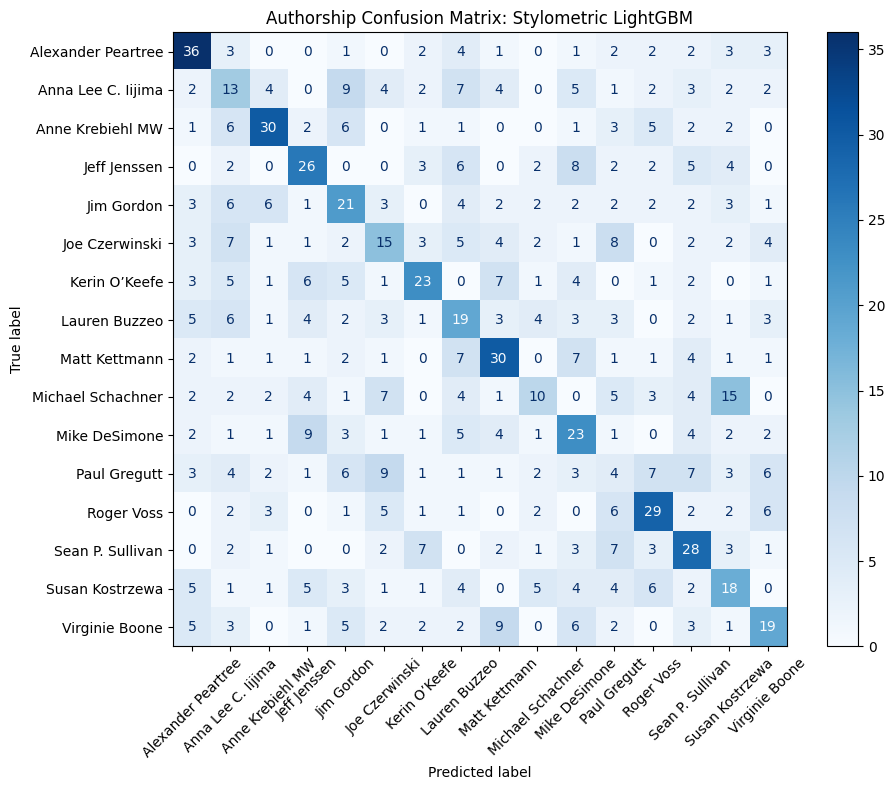

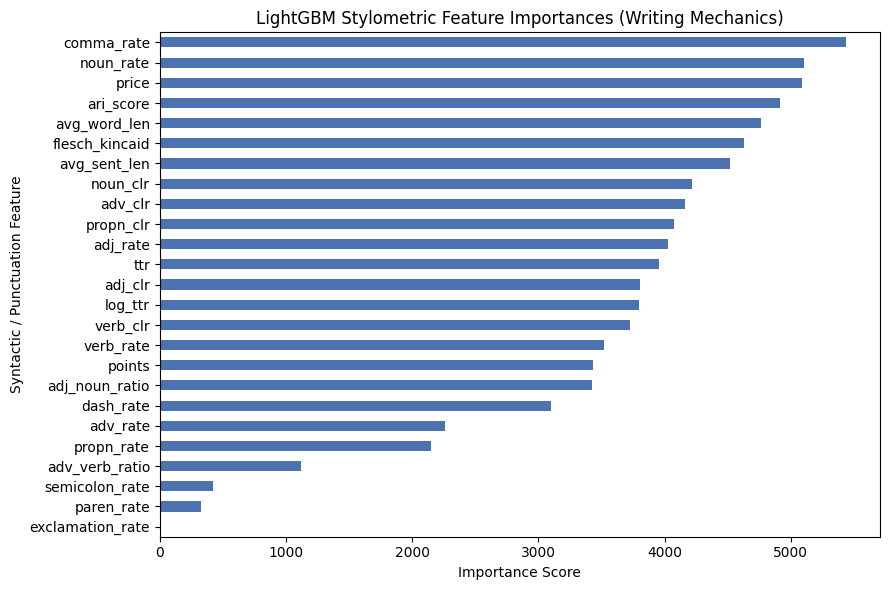

In [16]:
# --- 1. Confusion Matrix ---
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, lgbm_pred, cmap="Blues", xticks_rotation=45, ax=ax
)
plt.title("Authorship Confusion Matrix: Stylometric LightGBM")
plt.tight_layout()
plt.show()

# --- 2. Feature Importances (Interpretable Writing Mechanics) ---
importances = best_lgbm.feature_importances_
feature_names = X_stylo.columns

feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
feat_imp.plot(kind="barh", color="#4C72B0")
plt.title("LightGBM Stylometric Feature Importances (Writing Mechanics)")
plt.xlabel("Importance Score")
plt.ylabel("Syntactic / Punctuation Feature")
plt.tight_layout()
plt.show()

,precision,recall,f1-score
Alexander Peartree,50.0%,60.0%,54.5%
Anna Lee C. Iijima,20.3%,21.7%,21.0%
Anne Krebiehl MW,55.6%,50.0%,52.6%
Jeff Jenssen,42.6%,43.3%,43.0%
Jim Gordon,31.3%,35.0%,33.1%
Joe Czerwinski,27.8%,25.0%,26.3%
Kerin O’Keefe,47.9%,38.3%,42.6%
Lauren Buzzeo,27.1%,31.7%,29.2%
Matt Kettmann,44.1%,50.0%,46.9%
Michael Schachner,31.2%,16.7%,21.7%


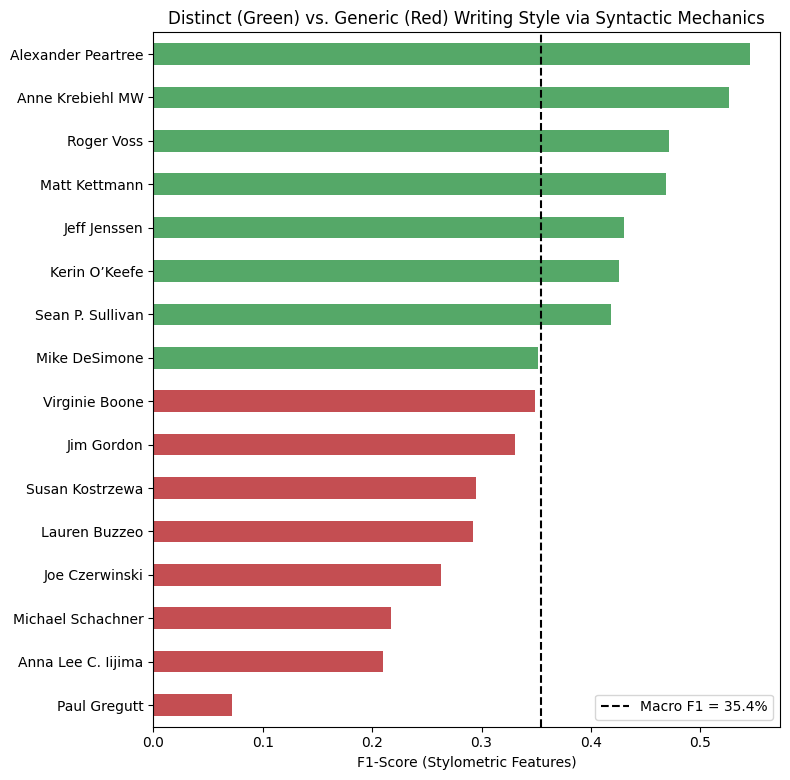

In [18]:
# Detailed per-author metrics to find who has a unique syntactic footprint vs. generic style
report = classification_report(y_test, lgbm_pred, digits=3, zero_division=0, output_dict=True)
per_author_df = pd.DataFrame(report).T.iloc[:-3, :3] # drop accuracy, macro avg, weighted avg
display(per_author_df.style.format({"precision": "{:.1%}", "recall": "{:.1%}", "f1-score": "{:.1%}"}))

# Distinct vs Generic Barplot
author_labels = np.sort(y.unique())

per_author_f1 = pd.Series(
    f1_score(y_test, lgbm_pred, labels=author_labels, average=None, zero_division=0),
    index=author_labels
).sort_values()

fig, ax = plt.subplots(figsize=(8, 0.4 * len(per_author_f1) + 1.5))
colors = ["#C44E52" if v < per_author_f1.median() else "#55A868" for v in per_author_f1]
per_author_f1.plot.barh(ax=ax, color=colors)

macro_f1_val = per_author_f1.mean()
ax.axvline(macro_f1_val, ls="--", c="black", label=f"Macro F1 = {macro_f1_val:.1%}")

ax.set_xlabel("F1-Score (Stylometric Features)")
ax.set_title("Distinct (Green) vs. Generic (Red) Writing Style via Syntactic Mechanics")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()